In [80]:
#Import required basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [81]:
#Load the dataset
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [82]:
#Drop customerID as it is a unique identifier and not useful for machine learning
df.drop('customerID', axis=1, inplace=True)

In [83]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [84]:
df.tail()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [86]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [87]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [88]:
#Handle missing values
# Convert TotalCharges to numeric, forcing errors to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [89]:
# Fill missing TotalCharges with the median value
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

In [90]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


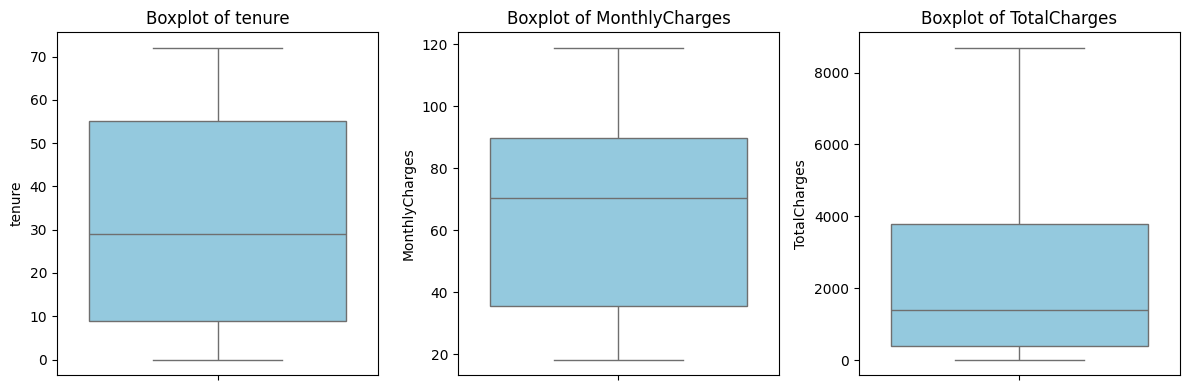

In [91]:
# Outlier Detection using Boxplots
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

plt.figure(figsize=(12, 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

In [92]:
# Handle Outliers using IQR (Interquartile Range) Capping
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap outliers
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])

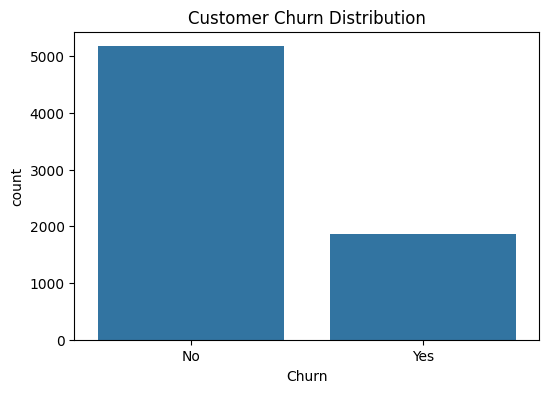

In [93]:
# Univariate Analysis: Target variable distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.show()

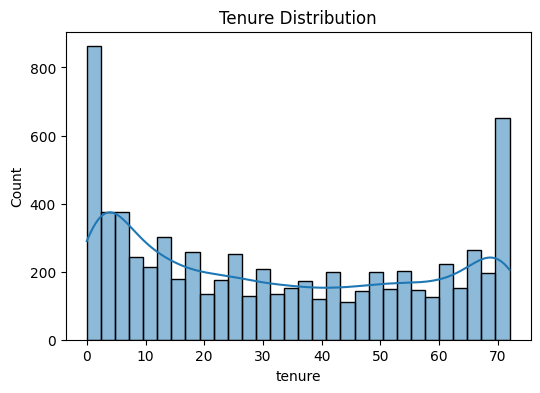

In [94]:
# Univariate Analysis: Tenure distribution
plt.figure(figsize=(6, 4))
sns.histplot(df['tenure'], bins=30, kde=True)
plt.title('Tenure Distribution')
plt.show()

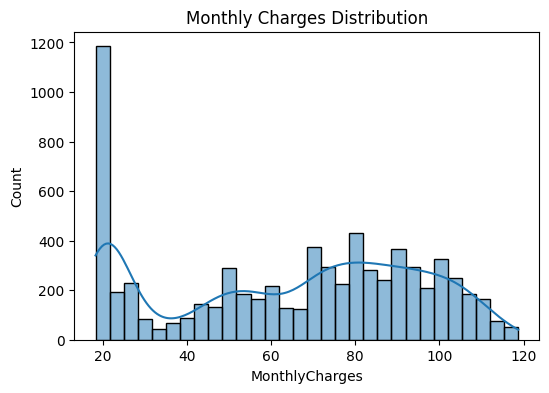

In [95]:
# Univariate Analysis: Monthly Charges distribution
plt.figure(figsize=(6, 4))
sns.histplot(df['MonthlyCharges'], bins=30, kde=True)
plt.title('Monthly Charges Distribution')
plt.show()

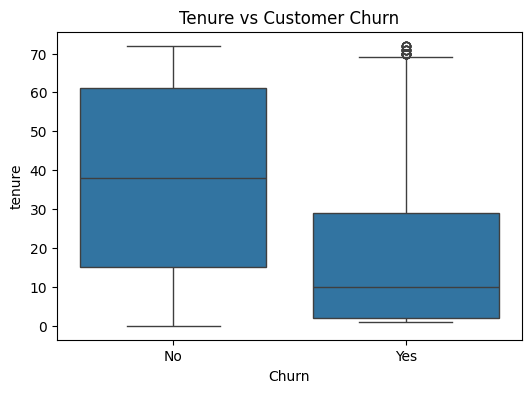

In [96]:
# Bivariate Analysis: Tenure vs Churn
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='Churn', y='tenure')
plt.title('Tenure vs Customer Churn')
plt.show()

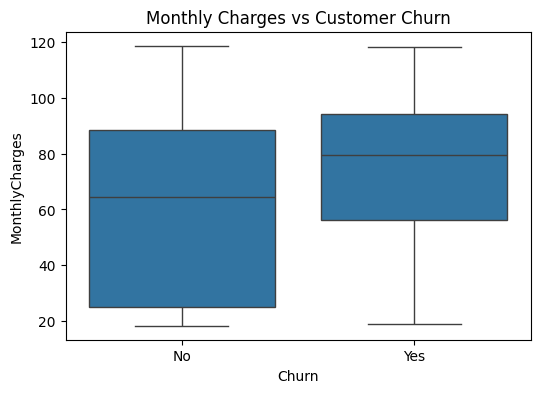

In [97]:
# Bivariate Analysis: Monthly Charges vs Churn
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges vs Customer Churn')
plt.show()

In [98]:
# Map the target variable to binary integers
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

In [99]:
from sklearn.model_selection import train_test_split

# List of categorical columns to one-hot encode
categorical_cols = [
    'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
    'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
    'PaperlessBilling', 'PaymentMethod'
]

In [100]:
# Apply one-hot encoding to the features
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [101]:
# Drop customerID as it is not a useful feature for prediction
if 'customerID' in df_encoded.columns:
    df_encoded = df_encoded.drop('customerID', axis=1)

In [102]:
# Split features (X) and target (y)
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

In [103]:
# Perform Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [104]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

#Train the initial Random Forest model
initial_rf = RandomForestClassifier(random_state=42)
initial_rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [105]:
#Perform cross-validation
cv_scores = cross_val_score(initial_rf, X_train, y_train, cv=5, scoring='accuracy')
print(f"Cross-Validation Mean Accuracy: {cv_scores.mean():.4f}")

Cross-Validation Mean Accuracy: 0.7893


In [106]:
from sklearn.model_selection import GridSearchCV

#Apply hyperparameter tuning
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100, 200]},
             scoring='accuracy')

In [107]:
#Select the best model
best_rf_model = grid_search.best_estimator_

In [108]:
# Check the results (leaving variables at the end to display them)
best_params = grid_search.best_params_
cv_scores.mean(), best_params

(np.float64(0.7893134920197131),
 {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200})

In [109]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
#Make predictions using the best model
y_pred = best_rf_model.predict(X_test)

In [110]:
# 6. Calculate all four evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [111]:
#Evaluate the model using appropriate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix")
print(conf_matrix)


Confusion Matrix
[[954  82]
 [178 195]]


In [112]:
# Display metrics as a clean DataFrame
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Score': [accuracy, precision, recall, f1]
})
display(metrics_df)

,Metric,Score
0,Accuracy,0.815472
1,Precision,0.703971
2,Recall,0.522788
3,F1-Score,0.600000


In [113]:
classification_metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

In [114]:
# Display evaluation metrics

print("\n--- Classification Metrics ---")

for metric, value in classification_metrics.items():
    print(f"{metric}: {value:.4f}")


--- Classification Metrics ---
Accuracy: 0.8155
Precision: 0.7040
Recall: 0.5228
F1-Score: 0.6000


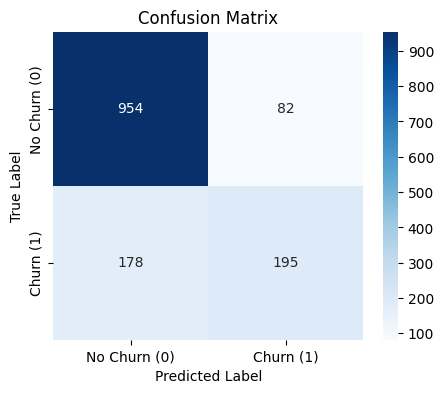

In [115]:
# Confusion Matrix Visualization
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

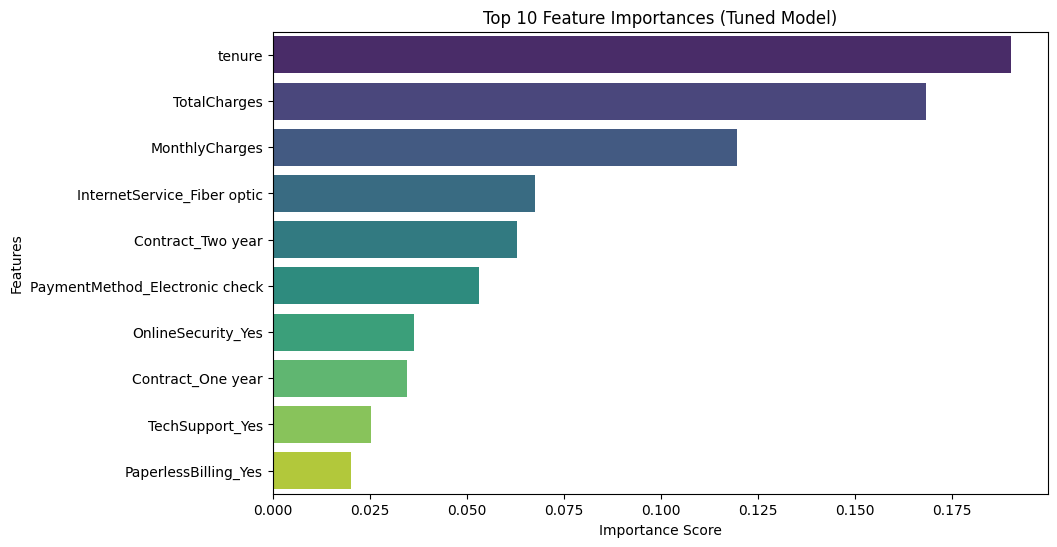

In [116]:
#Calculate and visualize feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importances.head(10), x='Importance', y='Feature', palette='viridis')
plt.title("Top 10 Feature Importances (Tuned Model)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [117]:
import joblib
#Save the final model using joblib
model_filename = "best_random_forest_churn_model.pkl"
joblib.dump(best_rf_model, model_filename)
print(f"Model successfully saved as {model_filename}")

Model successfully saved as best_random_forest_churn_model.pkl


In [118]:
print("\n--- Conclusion ---")
print("The Random Forest model effectively identified patterns leading to customer churn.\n"
      "Data preprocessing resolved missing values in the TotalCharges column.\n"
      "Evaluation metrics show solid overall accuracy.\n"
      "Based on the feature importance analysis, Total Charges, Monthly Charges, and Customer Tenure\n"
      "are the most significant drivers in predicting whether a customer will cancel their telecommunication service.\n")


--- Conclusion ---
The Random Forest model effectively identified patterns leading to customer churn.
Data preprocessing resolved missing values in the TotalCharges column.
Evaluation metrics show solid overall accuracy.
Based on the feature importance analysis, Total Charges, Monthly Charges, and Customer Tenure
are the most significant drivers in predicting whether a customer will cancel their telecommunication service.

